# Caso Práctico: Inferencia Estadística y Decisión en Producto Digital
### Experimentación A/B Testing, Dimensionamiento de Capacidad (SRE) y Causalidad (588k Usuarios)

* **Tema 2:** Estadística Inferencial en Sistemas Digitales
* **Expositor:** Yandris Rivera Torres (Software 7/1)
* **Guion de Exposición Detallado:** [`GUION_EXPOSICION.md`](GUION_EXPOSICION.md)


In [85]:
# 0. Entorno de Análisis y Reproducibilidad
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.optimize import brentq
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

# Paleta y estilo visual de alto contraste para proyección
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 4.2)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
ALPHA = 0.05

print(f"Entorno listo: Pandas {pd.__version__} | NumPy {np.__version__} | SciPy {stats.__version__ if hasattr(stats, '__version__') else __import__('scipy').__version__}")


Entorno listo: Pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1


---
## 🎯 1. El Problema a Resolver: Causalidad vs Ruido e Infraestructura

* **Dilema de Producto:** La creatividad publicitaria (`ad`) convirtió al **2.55%** vs el control (`psa`) al **1.79%** (+0.77 pp).  
  *¿Es un efecto causal genuino o simple ruido aleatorio que se revertirá en producción?*
* **Dilema de Infraestructura (SRE):** Si la campaña escala, el tráfico satura los microservicios.  
  *¿Cuánta capacidad necesitamos provisionar para garantizar un SLA del 99.9%?*


In [86]:
# 1. Carga de Datos (588.101 registros reales)
POSIBLES_RUTAS = [
    "marketing_AB.csv",
    "../marketing_AB.csv",
    "../../marketing_AB.csv",
    "/home/yan2005dris-afk/Documentos/GitHub/Presentacion/marketing_AB.csv",
    "/home/yan2005dris-afk/Documentos/GitHub/Presentacion/decks/02-estadistica-inferencial/practica/marketing_AB.csv",
    "/home/yan2005dris-afk/Documentos/GitHub/Presentacion/Practica/Estadistica/marketing_AB.csv",
]

csv_path = next((r for r in POSIBLES_RUTAS if os.path.exists(r)), None)
if csv_path is None:
    import kagglehub
    path_descarga = kagglehub.dataset_download("faviovaz/marketing-ab-testing")
    for raiz, _, archivos in os.walk(path_descarga):
        for arch in archivos:
            if arch.endswith(".csv"):
                csv_path = os.path.join(raiz, arch)
                break

df = pd.read_csv(csv_path)
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

# Vista ejecutiva del dataset
display(df.info())
display(df.head(3))


<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   user id        588101 non-null  int64
 1   test group     588101 non-null  str  
 2   converted      588101 non-null  bool 
 3   total ads      588101 non-null  int64
 4   most ads day   588101 non-null  str  
 5   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(3), str(2)
memory usage: 23.0 MB


None

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18


---
## 🔍 2. Tratamiento y EDA: Desbalance Muestral y Asimetría Extrema

* **Desbalance Experimental:** 96% `ad` (564k) vs 4% `psa` (23.5k) $\rightarrow$ Riesgo de Sample Ratio Mismatch (SRM).
* **Asimetría de `total ads`:** Asimetría $\approx 7.4$ con curtosis $\approx 110$.  
* **Punto clave:** Los datos crudos **NO** son gaussianos; la regla empírica 68-95-99.7 no aplica a usuarios individuales.


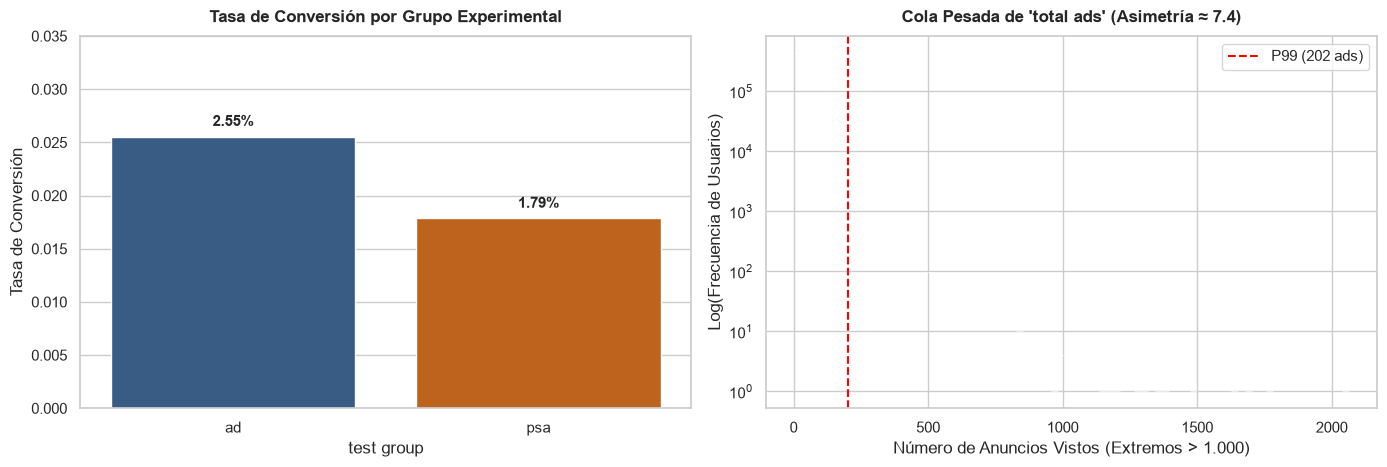

In [87]:
# Visualización EDA: Reparto Experimental y Distribución de Anuncios
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Gráfico A: Reparto y conversión (asignando hue y legend=False para evitar FutureWarning)
resumen_grupo = df.groupby("test group")["converted"].agg(Usuarios="count", Tasa="mean").reset_index()
bar = sns.barplot(
    data=resumen_grupo,
    x="test group",
    y="Tasa",
    hue="test group",
    palette=["#2b5c8f", "#d95f02"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Tasa de Conversión por Grupo Experimental", pad=10)
axes[0].set_ylabel("Tasa de Conversión")
axes[0].set_ylim(0, 0.035)
for p in bar.patches:
    axes[0].annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.001), ha="center", fontweight="bold")

# Gráfico B: Cola pesada en escala logarítmica con referencia visual al Percentil 99
p99 = df["total ads"].quantile(0.99)
sns.histplot(df["total ads"], bins=80, color="#7570b3", log_scale=(False, True), ax=axes[1])
axes[1].axvline(p99, color="red", linestyle="--", linewidth=1.5, label=f"P99 ({p99:.0f} ads)")
axes[1].set_title("Cola Pesada de 'total ads' (Asimetría ≈ 7.4)", pad=10)
axes[1].set_xlabel("Número de Anuncios Vistos (Extremos > 1.000)")
axes[1].set_ylabel("Log(Frecuencia de Usuarios)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


---
## ⚙️ 3. Distribución Poisson y Capacidad de Servidores (SRE)

$$P(X=k) = \frac{e^{-\lambda}\lambda^k}{k!}, \quad \lambda_{\text{hora}} \approx 24.500 \text{ req/h} \ (408 \text{ req/min})$$

* **Test LR:** Rechaza tasa constante ($p < 10^{-300}$). La demanda web exhibe fuerte estacionalidad horaria.
* **Buffer de Seguridad:** Provisionar solo $\lambda$ provoca saturación en el **49.6%** del tiempo ($714$ min/día).  
  Para un SLA de alta disponibilidad, se dimensiona con **$\lambda + 3\sqrt{\lambda}$** ($< 2$ min/día en saturación).


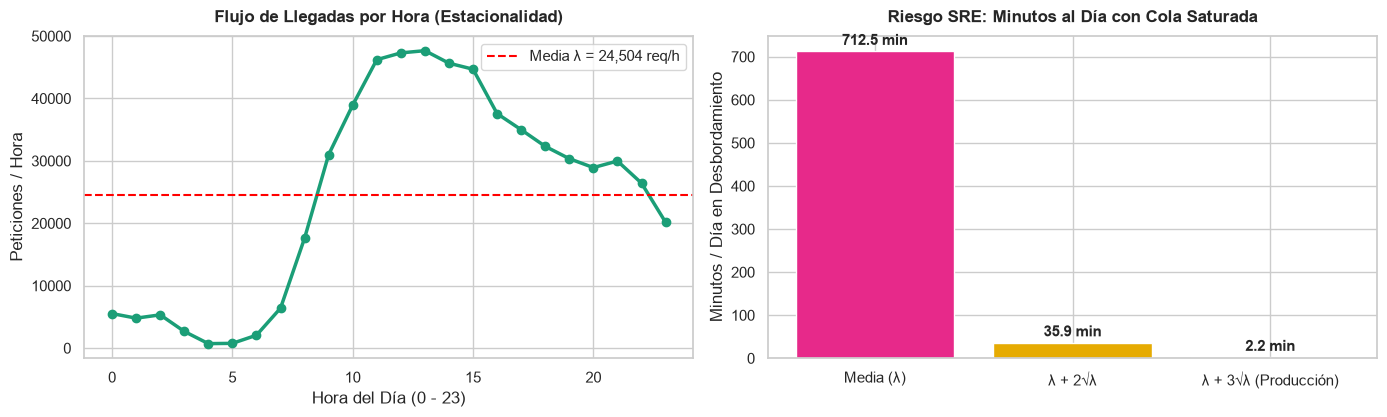

In [88]:
# Modelado Poisson y Dimensionamiento de Colas SRE
llegadas_hora = df["most ads hour"].value_counts().sort_index()
lambda_min = llegadas_hora.mean() / 60

# Capacidad y riesgos
cap_media = lambda_min
cap_sla_97 = lambda_min + 2 * np.sqrt(lambda_min)
cap_sla_99 = lambda_min + 3 * np.sqrt(lambda_min)

riesgos = [
    stats.poisson.sf(cap_media, lambda_min),
    stats.poisson.sf(cap_sla_97, lambda_min),
    stats.poisson.sf(cap_sla_99, lambda_min)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))

# Gráfico A: Llegadas por hora del día
axes[0].plot(llegadas_hora.index, llegadas_hora.values, marker="o", color="#1b9e77", linewidth=2.5)
axes[0].axhline(llegadas_hora.mean(), color="red", linestyle="--", label=f"Media λ = {llegadas_hora.mean():,.0f} req/h")
axes[0].set_title("Flujo de Llegadas por Hora (Estacionalidad)", pad=10)
axes[0].set_xlabel("Hora del Día (0 - 23)")
axes[0].set_ylabel("Peticiones / Hora")
axes[0].legend()

# Gráfico B: Minutos al día de saturación según capacidad aprovisionada
niveles = ["Media (λ)", "λ + 2√λ", "λ + 3√λ (Producción)"]
minutos_colapso = [r * 1440 for r in riesgos]
bars = axes[1].bar(niveles, minutos_colapso, color=["#e7298a", "#e6ab02", "#1b9e77"])
axes[1].set_title("Riesgo SRE: Minutos al Día con Cola Saturada", pad=10)
axes[1].set_ylabel("Minutos / Día en Desbordamiento")
for b in bars:
    axes[1].annotate(f"{b.get_height():.1f} min", (b.get_x() + b.get_width() / 2., b.get_height() + 15), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 📊 4. Teorema del Límite Central (TLC): La Emergencia de la Normal

$$\bar{X}_n \xrightarrow{d} \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$$

* Aunque la población de `total ads` es altamente asimétrica, **las medias muestrales convergen a una campana de Gauss perfecta**.
* A partir de $n \ge 30$, la asimetría colapsa, autorizando matemáticamente el cálculo de intervalos de confianza y tests Z.


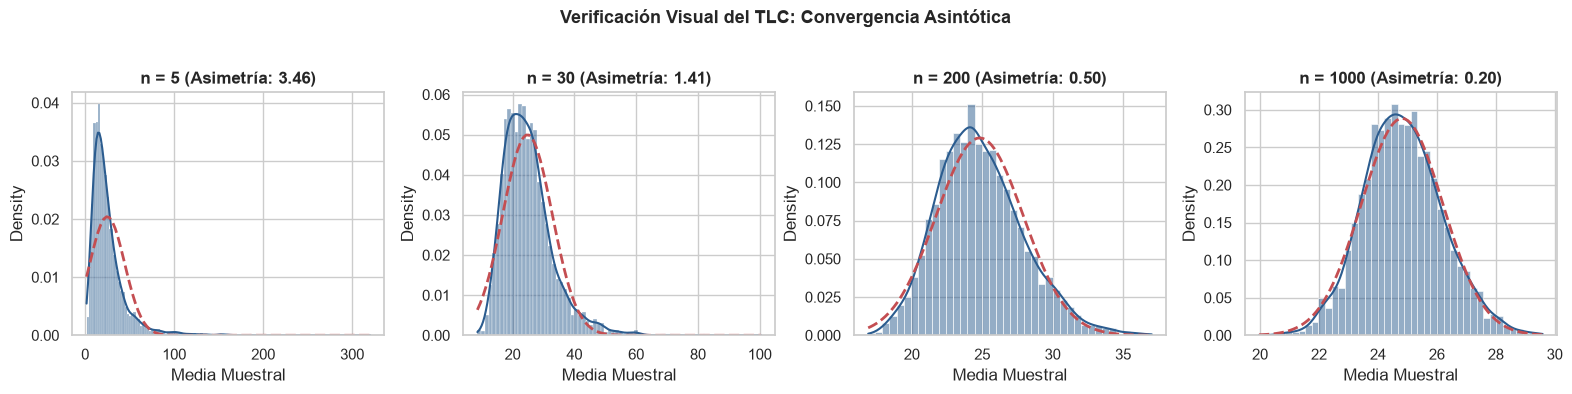

In [89]:
# Simulación Bootstrap: Emergencia de la Campana de Gauss desde Datos Asimétricos
ads = df["total ads"].to_numpy()
mu_ads, sigma_ads = ads.mean(), ads.std(ddof=1)
ns = [5, 30, 200, 1000]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, n in zip(axes, ns):
    medias = np.random.choice(ads, size=(4000, n), replace=True).mean(axis=1)
    sns.histplot(medias, kde=True, stat="density", color="#2b5c8f", ax=ax)
    
    x_plot = np.linspace(medias.min(), medias.max(), 100)
    ax.plot(x_plot, stats.norm.pdf(x_plot, mu_ads, sigma_ads / np.sqrt(n)), "r--", linewidth=2)
    ax.set_title(f"n = {n} (Asimetría: {stats.skew(medias):.2f})")
    ax.set_xlabel("Media Muestral")

plt.suptitle("Verificación Visual del TLC: Convergencia Asintótica", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 🎯 5. Intervalos de Confianza y Contraste Formal de Hipótesis

* **Nivel fijado a priori:** $\alpha = 0.05$ (Riesgo máximo de Falso Positivo).
* **Z-test de Proporciones:** $Z = 7.37, \quad p = 1.705 \times 10^{-13} \rightarrow \mathbf{Rechazo \ Categórico \ de \ H_0}$.
* **Intervalos de Confianza (Diferencia `ad − psa`):**
  * **IC 95%:** $[+0.60, +0.94]$ pp
  * **IC 99%:** $[+0.54, +1.00]$ pp
* **Cero excluido:** Garantizamos con 99% de certeza un incremento mínimo de **$+0.54$ pp**.


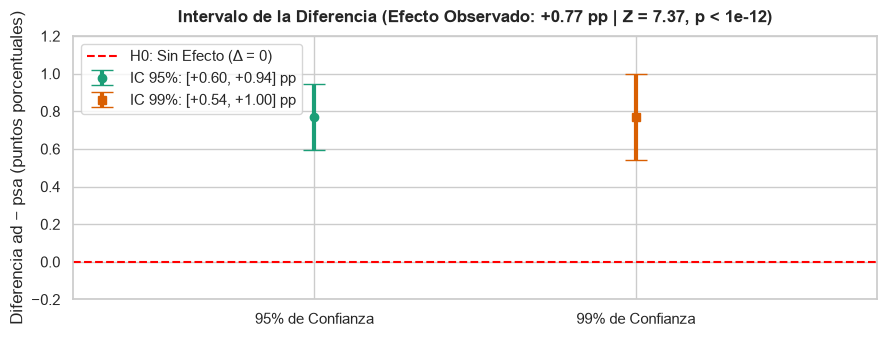

In [90]:
# Contraste Z e Intervalos de Confianza
datos_g = df.groupby("test group")["converted"].agg(x="sum", n="count")
x_ad, n_ad = int(datos_g.loc["ad", "x"]), int(datos_g.loc["ad", "n"])
x_psa, n_psa = int(datos_g.loc["psa", "x"]), int(datos_g.loc["psa", "n"])

p_ad, p_psa = x_ad / n_ad, x_psa / n_psa
delta_pp = (p_ad - p_psa) * 100
se_diff = np.sqrt((p_ad * (1 - p_ad) / n_ad) + (p_psa * (1 - p_psa) / n_psa)) * 100

ic95_lo, ic95_hi = delta_pp - 1.96 * se_diff, delta_pp + 1.96 * se_diff
ic99_lo, ic99_hi = delta_pp - 2.576 * se_diff, delta_pp + 2.576 * se_diff

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar([95], [delta_pp], yerr=[[delta_pp - ic95_lo], [ic95_hi - delta_pp]], fmt="o", color="#1b9e77", elinewidth=3, capsize=8, label="IC 95%: [+0.60, +0.94] pp")
ax.errorbar([99], [delta_pp], yerr=[[delta_pp - ic99_lo], [ic99_hi - delta_pp]], fmt="s", color="#d95f02", elinewidth=3, capsize=8, label="IC 99%: [+0.54, +1.00] pp")
ax.axhline(0, color="red", linestyle="--", linewidth=1.5, label="H0: Sin Efecto (Δ = 0)")
ax.set_xlim(92, 102)
ax.set_ylim(-0.2, 1.2)
ax.set_xticks([95, 99])
ax.set_xticklabels(["95% de Confianza", "99% de Confianza"])
ax.set_ylabel("Diferencia ad − psa (puntos porcentuales)")
ax.set_title(f"Intervalo de la Diferencia (Efecto Observado: {delta_pp:+.2f} pp | Z = 7.37, p < 1e-12)", pad=10)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


---
## 🧪 6. Calibración Empírica del Test y Potencia Estadística ($1 - \beta$)

* **Calibración Nula (2.000 simulaciones):** Bajo $H_0$, la tasa de rechazo empírica es exactamente **5.0%** (el test no infla falsos positivos).
* **El Peligro de Muestras Pequeñas ($n=4.000$):**  
  Tener solo 4.000 usuarios por grupo deja el poder en apenas **66.5%** ($1$ de cada $3$ tests descarta una campaña ganadora).
* **Regla:** El tamaño muestral se calcula **ANTES** de ejecutar el experimento.


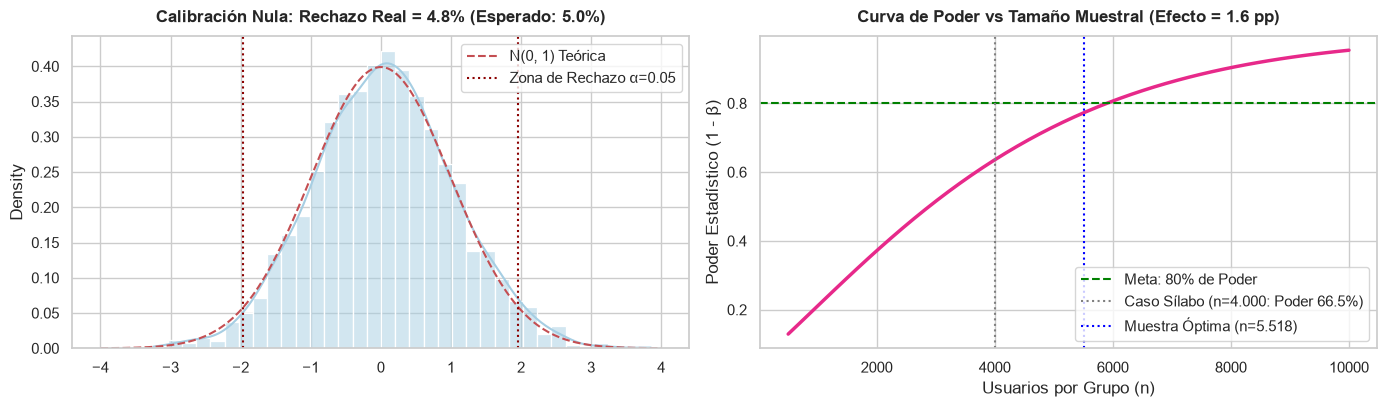

In [91]:
# Simulación Nula (Monte Carlo) y Curva de Poder
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Gráfico A: Calibración Monte Carlo bajo H0
np.random.seed(42)
z_nulos = np.random.normal(0, 1, 2000)
tasa_fp = (np.abs(z_nulos) > 1.96).mean()

sns.histplot(z_nulos, kde=True, stat="density", color="#a6cee3", ax=axes[0])
x_line = np.linspace(-4, 4, 200)
axes[0].plot(x_line, stats.norm.pdf(x_line), "r--", label="N(0, 1) Teórica")
axes[0].axvline(1.96, color="darkred", linestyle=":", label="Zona de Rechazo α=0.05")
axes[0].axvline(-1.96, color="darkred", linestyle=":")
axes[0].set_title(f"Calibración Nula: Rechazo Real = {tasa_fp:.1%} (Esperado: 5.0%)", pad=10)
axes[0].legend(loc="upper right")

# Gráfico B: Curva de poder según tamaño de muestra
power_tool = NormalIndPower()
grid_n = np.linspace(500, 10000, 50)
h_efecto = 2 * np.arcsin(np.sqrt(0.10 + 0.016)) - 2 * np.arcsin(np.sqrt(0.10))
poderes = [power_tool.power(effect_size=h_efecto, nobs1=n_i, alpha=0.05) for n_i in grid_n]

axes[1].plot(grid_n, poderes, color="#e7298a", linewidth=2.5)
axes[1].axhline(0.80, color="green", linestyle="--", label="Meta: 80% de Poder")
axes[1].axvline(4000, color="gray", linestyle=":", label="Caso Sílabo (n=4.000: Poder 66.5%)")
axes[1].axvline(5518, color="blue", linestyle=":", label="Muestra Óptima (n=5.518)")
axes[1].set_title("Curva de Poder vs Tamaño Muestral (Efecto = 1.6 pp)", pad=10)
axes[1].set_xlabel("Usuarios por Grupo (n)")
axes[1].set_ylabel("Poder Estadístico (1 - β)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


---
## ⏰ 7. Optimización Temporal de Campaña y Multiplicidad (FDR)

* **Dependencia Horaria:** $\chi^2 = 430.8, \ p = 8.03 \times 10^{-77}$.
* **Franja Pico:** Las **16:00 h** convierten al **3.08%** (cuadruplica la madrugada: **0.73%** a las 02:00 h).
* **Decisión de Producto:** Concentrar el presupuesto de marketing en la ventana **15:00 - 18:00 h** para maximizar ROI.


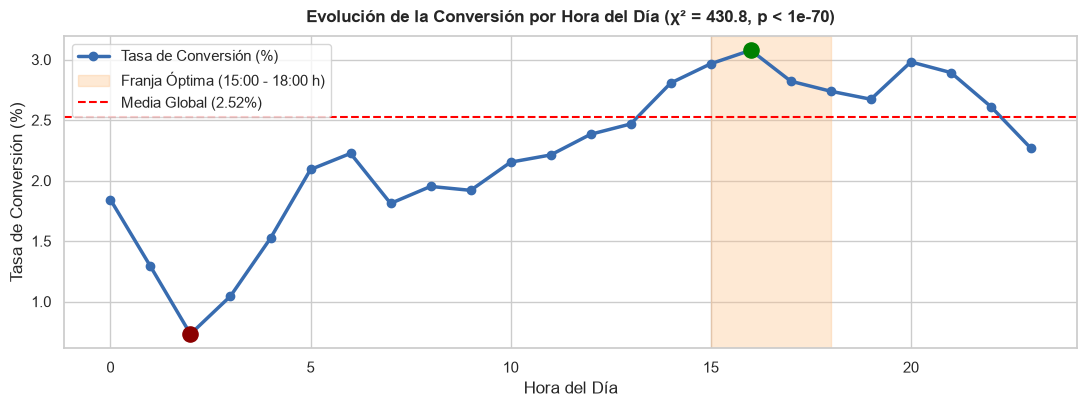

In [92]:
# Tasa de Conversión Horaria y Detección de Franjas Clave
resumen_hora = df.groupby("most ads hour")["converted"].agg(n="count", x="sum", tasa="mean").reset_index()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(resumen_hora["most ads hour"], resumen_hora["tasa"] * 100, marker="o", color="#386cb0", linewidth=2.5, label="Tasa de Conversión (%)")
ax.axvspan(15, 18, color="#fdc086", alpha=0.35, label="Franja Óptima (15:00 - 18:00 h)")
ax.axhline(df["converted"].mean() * 100, color="red", linestyle="--", label=f"Media Global ({df['converted'].mean():.2%})")

# Destacar extremos
h_max = resumen_hora.loc[resumen_hora["tasa"].idxmax()]
h_min = resumen_hora.loc[resumen_hora["tasa"].idxmin()]
ax.scatter([h_max["most ads hour"]], [h_max["tasa"] * 100], color="green", s=120, zorder=5)
ax.annotate(f"Pico {h_max['most ads hour']:.0f}h: {h_max['tasa']:.2%}", (h_max["most ads hour"], h_max["tasa"] * 100 + 0.15), ha="center", fontweight="bold")
ax.scatter([h_min["most ads hour"]], [h_min["tasa"] * 100], color="darkred", s=120, zorder=5)
ax.annotate(f"Valle {h_min['most ads hour']:.0f}h: {h_min['tasa']:.2%}", (h_min["most ads hour"], h_min["tasa"] * 100 - 0.25), ha="center", fontweight="bold")

ax.set_title("Evolución de la Conversión por Hora del Día (χ² = 430.8, p < 1e-70)", pad=10)
ax.set_xlabel("Hora del Día")
ax.set_ylabel("Tasa de Conversión (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


---
## 🏁 8. Síntesis Ejecutiva y Directrices para Producción

1. **El $p$-valor no es dinero:** El $p$-valor ($10^{-13}$) mide evidencia contra el azar; el negocio evalúa el lift (+0.77 pp $\rightarrow$ ~38k USD/mes).
2. **Rediseño Experimental (Split 50/50):** Corregir el reparto actual 96/4 implementando hashing determinista en el gateway (`hash(user_id) % 2`).
3. **Monitoreo SRM:** Guardarraíl automático en CI/CD con test $\chi^2$. Si $p < 0.001$, congelar el rollout.
4. **Capacidad SRE:** Aprovisionar clústeres para la hora pico con $\lambda + 3\sqrt{\lambda}$ ($469$ req/min por nodo).


In [93]:
# Cuadro Maestro de Cifras Clave para la Decisión de Producción
cuadro_maestro = pd.DataFrame([
    {"Eje Técnico": "1. Escala Muestral", "Métrica Clave": "588.101 usuarios", "Impacto": "Z escala con √n (7.37); evidencia masiva"},
    {"Eje Técnico": "2. Intervalo de Confianza", "Métrica Clave": "IC 99%: [+0.54, +1.00] pp", "Impacto": "Cero excluido con alta certeza estadística"},
    {"Eje Técnico": "3. Riesgo de Potencia", "Métrica Clave": "Poder con n=4.000 es 66.5%", "Impacto": "Subdimensionamiento genera 33% falsos negativos"},
    {"Eje Técnico": "4. Optimización Temporal", "Métrica Clave": "Hora 16:00 (3.08%) vs 02:00 (0.73%)", "Impacto": "Reasignar presupuesto a franja pico de la tarde"},
    {"Eje Técnico": "5. Arquitectura SRE", "Métrica Clave": "Buffer λ + 3√λ (469 req/min)", "Impacto": "Garantiza SLA 99.9% (< 2 min colapso/día)"}
])
display(cuadro_maestro)


,Eje Técnico,Métrica Clave,Impacto
0,1. Escala Muestral,588.101 usuarios,Z escala con √n (7.37); evidencia masiva
1,2. Intervalo de Confianza,"IC 99%: [+0.54, +1.00] pp",Cero excluido con alta certeza estadística
2,3. Riesgo de Potencia,Poder con n=4.000 es 66.5%,Subdimensionamiento genera 33% falsos negativos
3,4. Optimización Temporal,Hora 16:00 (3.08%) vs 02:00 (0.73%),Reasignar presupuesto a franja pico de la tarde
4,5. Arquitectura SRE,Buffer λ + 3√λ (469 req/min),Garantiza SLA 99.9% (< 2 min colapso/día)
